#E-Commerce Customer Churn
## Deskripsi Dataset

Dataset **E-Commerce Customer Churn Analysis and Prediction** berisi 5.630 data pelanggan sebuah platform e-commerce, mencakup perilaku transaksi, penggunaan aplikasi, dan karakteristik pelanggan. Tujuannya memprediksi apakah pelanggan akan berhenti bertransaksi (*churn*) atau tidak. Sumber: [Kaggle - Ankit Verma](https://www.kaggle.com/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction).

| Nama Kolom | Tipe Data | Deskripsi |
|---|---|---|
| `CustomerID` | int64 | ID unik untuk setiap pelanggan |
| `Churn` | int64 | Status churn pelanggan, target prediksi (1 = churn, 0 = tidak churn) |
| `Tenure` | float64 | Lama pelanggan telah menggunakan platform |
| `PreferredLoginDevice` | object | Perangkat yang paling sering digunakan pelanggan untuk login |
| `CityTier` | int64 | Tingkatan kota tempat tinggal pelanggan |
| `WarehouseToHome` | float64 | Jarak antara gudang dan rumah pelanggan |
| `PreferredPaymentMode` | object | Metode pembayaran yang paling disukai pelanggan |
| `Gender` | object | Jenis kelamin pelanggan |
| `HourSpendOnApp` | float64 | Jumlah jam yang dihabiskan pelanggan di aplikasi seluler atau situs web |
| `NumberOfDeviceRegistered` | int64 | Jumlah perangkat yang terdaftar pada akun pelanggan |
| `PreferedOrderCat` | object | Kategori pesanan yang paling disukai pelanggan pada bulan terakhir |
| `SatisfactionScore` | int64 | Skor kepuasan pelanggan terhadap layanan (skala 1-5) |
| `MaritalStatus` | object | Status pernikahan pelanggan |
| `NumberOfAddress` | int64 | Jumlah alamat yang ditambahkan pada akun pelanggan |
| `Complain` | int64 | Apakah pelanggan mengajukan keluhan pada bulan terakhir (1 = ya, 0 = tidak) |
| `OrderAmountHikeFromlastYear` | float64 | Persentase kenaikan nilai pesanan dibandingkan tahun lalu |
| `CouponUsed` | float64 | Jumlah kupon yang digunakan pelanggan pada bulan terakhir |
| `OrderCount` | float64 | Jumlah pesanan yang dilakukan pelanggan pada bulan terakhir |
| `DaySinceLastOrder` | float64 | Jumlah hari sejak pesanan terakhir pelanggan |
| `CashbackAmount` | int64 | Rata-rata cashback yang diterima pelanggan pada bulan terakhir |

## Peta Alur (CRISP-DM)

Notebook ini mengikuti enam fase **CRISP-DM** (Cross-Industry Standard Process for Data Mining).

### 1. Business Understanding
Platform e-commerce ingin menekan angka **churn** (pelanggan berhenti bertransaksi). Churn awalnya hanya **16,8%** dari data, sehingga model yang memprediksi "semua tidak churn" akan terlihat akurat (83,2%) tetapi **recall 0%** — tidak berguna bagi bisnis.

Keputusan bisnis yang mendasari pemodelan:

| Kesalahan | Arti bisnis | Biaya |
|---|---|---|
| **FN** — pelanggan churn tidak terdeteksi | Kehilangan pelanggan | **Rp 67.680** |
| **FP** — pelanggan sehat dikira churn | Kampanye retensi sia-sia | **Rp 14.700** |

Rasio biaya ≈ **4,6 : 1**, maka **recall dijadikan metrik utama** saat tuning, dan fungsi biaya `FN×67.680 + FP×14.700` dipakai saat memilih threshold.

### 2. Peta alur notebook

```text
Deskripsi Dataset         → Business Understanding
Explanatory EDA           → Data Understanding (distribusi, duplikat, mapping)
Splitting Data            → Data Preparation (train / test / fit / val)
EDA Data Train            → Data Understanding lanjutan (train saja)
MODELING                  → Data Preparation (pipeline) + Modeling (base model)
Final Model (Tuning)      → Modeling (RandomizedSearchCV di X_fit)
Threshold                 → Modeling (cost-sensitive threshold di X_val)
Evaluasi + Learning Curve → Evaluation (test sekali + diagnosis overfitting)
SHAP & Feature Importance → Evaluation (interpretasi)
Saving Model & Streamlit  → Deployment
```

---



In [38]:
pip install category_encoders

In [39]:
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import warnings
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV,
    cross_validate, cross_val_predict, learning_curve
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, RobustScaler
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, make_scorer,
    recall_score, roc_auc_score, RocCurveDisplay
)
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')

In [40]:
drive.mount('/content/drive')
path = '/content/drive/MyDrive/Dataset Capstone 3/E Commerce Dataset.xlsx'
df = pd.read_excel(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Explanatory Data Analysis

In [41]:
df.shape

(5630, 20)

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [43]:
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [44]:
df.describe()

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5630.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52815.500000,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,177.223030
std,1625.385339,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,49.207036
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51408.250000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,52815.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.280000
75%,54222.750000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.392500
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,324.990000


array([[<Axes: title={'center': 'CustomerID'}>,
        <Axes: title={'center': 'Churn'}>,
        <Axes: title={'center': 'Tenure'}>,
        <Axes: title={'center': 'CityTier'}>],
       [<Axes: title={'center': 'WarehouseToHome'}>,
        <Axes: title={'center': 'HourSpendOnApp'}>,
        <Axes: title={'center': 'NumberOfDeviceRegistered'}>,
        <Axes: title={'center': 'SatisfactionScore'}>],
       [<Axes: title={'center': 'NumberOfAddress'}>,
        <Axes: title={'center': 'Complain'}>,
        <Axes: title={'center': 'OrderAmountHikeFromlastYear'}>,
        <Axes: title={'center': 'CouponUsed'}>],
       [<Axes: title={'center': 'OrderCount'}>,
        <Axes: title={'center': 'DaySinceLastOrder'}>,
        <Axes: title={'center': 'CashbackAmount'}>, <Axes: >]],
      dtype=object)

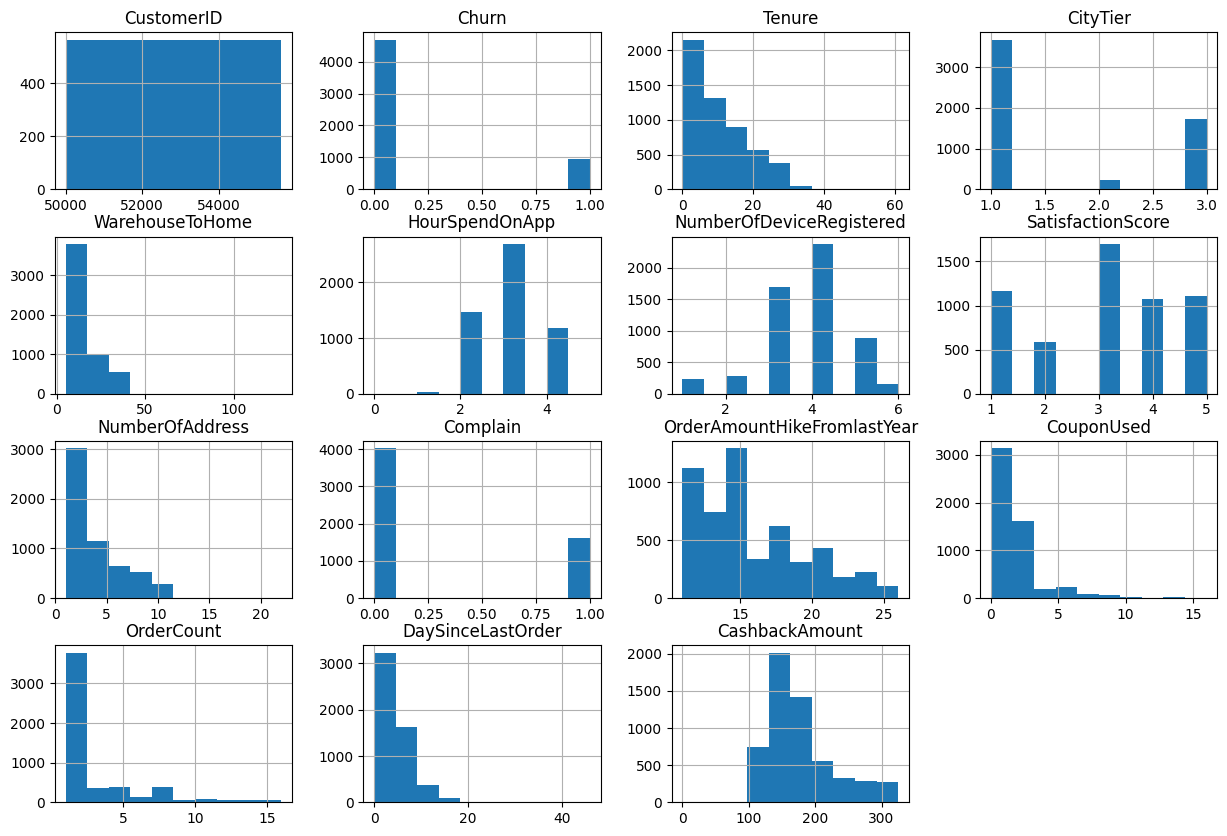

In [45]:
df.hist(figsize=(15,10))

In [46]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
  print(f'=== {col} ===')
  print(df[col].value_counts(dropna=False), '\n')

=== PreferredLoginDevice ===
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64 

=== PreferredPaymentMode ===
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64 

=== Gender ===
Gender
Male      3384
Female    2246
Name: count, dtype: int64 

=== PreferedOrderCat ===
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264
Name: count, dtype: int64 

=== MaritalStatus ===
MaritalStatus
Married     2986
Single      1796
Divorced     848
Name: count, dtype: int64 



In [47]:
df = df.set_index('CustomerID')
label_map = {
    'PreferedOrderCat': {'Mobile': 'Mobile Phone'},
    'PreferredLoginDevice': {'Phone': 'Mobile Phone'},
    'PreferredPaymentMode': {'CC': 'Credit Card', 'COD': 'Cash on Delivery',
                             'UPI': 'Unified Payments Interface'}
}

for col, mapping in label_map.items():
  df[col] = df[col].replace(mapping)

for col in label_map:
  print(f'=== {col} ===')
  print(df[col].value_counts(), '\n')

=== PreferedOrderCat ===
PreferedOrderCat
Mobile Phone          2080
Laptop & Accessory    2050
Fashion                826
Grocery                410
Others                 264
Name: count, dtype: int64 

=== PreferredLoginDevice ===
PreferredLoginDevice
Mobile Phone    3996
Computer        1634
Name: count, dtype: int64 

=== PreferredPaymentMode ===
PreferredPaymentMode
Debit Card                    2314
Credit Card                   1774
E wallet                       614
Cash on Delivery               514
Unified Payments Interface     414
Name: count, dtype: int64 



### Mapping Pada 2 Kolom

Dataset asli memiliki beberapa ejaan untuk kategori yang sama, misalnya `Mobile` dan `Mobile Phone`, `Phone` dan `Mobile Phone`.

Jika dibiarkan, saat melakukan encoding model akan melihat 'Mobile' dan 'Mobile Phone' sebagai dua kategori yang berbeda, sehingga sinyal target terpecah dan encoding menjadi kurang stabil.

Mapping ini dilakukan **sebelum** pembagian data karena merupakan normalisasi nilai.

In [48]:
n_dup = df.duplicated().sum()
print(f'Total Duplikat (Selain ID): {n_dup}')

df = df.drop_duplicates()
print(f'Setelah duplikat dihapus: {df.shape}')

Total Duplikat (Selain ID): 557
Setelah duplikat dihapus: (5073, 19)


Ada 557 baris duplikat (Customer ID tidak dihitung) yang dihapus. Hal ini dilakukan untuk mencegah **data leakage**.

#Splitting Data

In [49]:
#New Feature
#Interaksi antara Tenure dan Complain
df['Tenure_Complain_Interaction'] = df['Tenure'] * df['Complain']

#Rasio Cashback terhadap Tenure (+1 untuk menghindari pembagian dengan nol)
df['Cashback_per_Tenure'] = df['CashbackAmount'] / (df['Tenure'] + 1)

### Feature engineering: dua fitur turunan

Dua fitur baru dibuat dari fitur yang sudah ada:

```python
Tenure_Complain_Interaction = Tenure × Complain
Cashback_per_Tenure         = CashbackAmount / (Tenure + 1)
```

**Alasan:**
- `Tenure_Complain_Interaction` menangkap interaksi antara lama berlangganan dan keluhan. Secara domain, komplain pada pelanggan baru dan pelanggan lama **mungkin** memiliki risiko churn yang berbeda.
- `Cashback_per_Tenure` mengukur intensitas cashback relatif terhadap lama berlangganan. `+1` ditambahkan untuk menghindari pembagian dengan nol ketika `Tenure = 0`.

---



In [50]:
feature = df.drop(columns = 'Churn')
target = df['Churn']

X_train, X_test, y_train, y_test = train_test_split( feature, target,
                                                    test_size = 0.2,
                                                     stratify = target,
                                                     random_state = 20)

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train,
                                              test_size=0.2,
                                              stratify=y_train,
                                              random_state=42)
print(f'Train: {X_train.shape}')
print(f'Test: {X_test.shape}')
print(f'Eval: {X_val.shape}')

Train: (4058, 20)
Test: (1015, 20)
Eval: (812, 20)


### Strategi pembagian data tiga arah

Data dibagi dua tahap:

```text
5.073 baris
 └── Train / Test = 80 / 20 (stratify, random_state=20)
      ├── Train = 4.058 → Fit (3.246) / Validation (812) (stratify, random_state=42)
      └── Test  = 1.015 → dikunci, dipakai sekali di akhir
```

**Kenapa tiga bagian?**
- **Fit** → melatih parameter model dan memilih hyperparameter.
- **Validation** → memilih threshold operasional dan memantau overfitting.
- **Test** → satu-satunya sumber estimasi performa akhir.

Dengan hanya train/test, setiap kali threshold atau model dibandingkan memakai data test, test diam-diam berubah menjadi validation set dan estimasi akhir menjadi bias optimistis.

**Kenapa `stratify`?** Rasio churn 16,8% harus terjaga di setiap bagian supaya metrik tidak terganggu oleh perbedaan komposisi kelas.

**Kenapa `random_state` berbeda (20 dan 42)?** Supaya pembagian kedua tidak kebetulan mengikuti pola pembagian pertama.

---



#Exploratory Data Analysis (Data Train)

### Statistik Deskriptif & Missing Values


In [51]:
train_df = pd.concat([X_train, y_train], axis=1)
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Tenure,3874.0,10.175787,8.573000,0.0,2.000000,9.000000,16.000000,61.00
CityTier,4058.0,1.661163,0.920971,1.0,1.000000,1.000000,3.000000,3.00
WarehouseToHome,3882.0,15.607419,8.705341,5.0,9.000000,13.000000,20.000000,127.00
HourSpendOnApp,3862.0,2.925168,0.729263,0.0,2.000000,3.000000,3.000000,5.00
NumberOfDeviceRegistered,4058.0,3.692213,1.027664,1.0,3.000000,4.000000,4.000000,6.00
SatisfactionScore,4058.0,3.038196,1.379904,1.0,2.000000,3.000000,4.000000,5.00
NumberOfAddress,4058.0,4.150813,2.533858,1.0,2.000000,3.000000,5.750000,21.00
Complain,4058.0,0.282159,0.450106,0.0,0.000000,0.000000,1.000000,1.00
OrderAmountHikeFromlastYear,3859.0,15.715989,3.691047,11.0,13.000000,15.000000,18.000000,26.00
CouponUsed,3894.0,1.764253,1.895794,0.0,1.000000,1.000000,2.000000,16.00


In [52]:
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
pd.DataFrame({'Missing Values': missing, 'Persentase (%)': missing_pct})[missing > 0]

,Missing Values,Persentase (%)
Tenure,184,4.53
WarehouseToHome,176,4.34
HourSpendOnApp,196,4.83
OrderAmountHikeFromlastYear,199,4.90
CouponUsed,164,4.04
OrderCount,194,4.78
DaySinceLastOrder,225,5.54
Tenure_Complain_Interaction,184,4.53
Cashback_per_Tenure,184,4.53


### Strategi missing value

Tujuh kolom memiliki missing sekitar **4–5,5%**.

Missing tidak diisi di sini. Pengisian dilakukan dengan **`KNNImputer` di dalam pipeline** pada bagian Modeling.

**Alasannya**: agar saat cross-validation, parameter imputer dipelajari **hanya dari fold latih**. Mengisi missing menggunakan seluruh dataset sebelum split akan memasukkan informasi statistik data validation/test ke dalam proses latih,yang merupakan bagian dari data leakage.

---



###Outlier

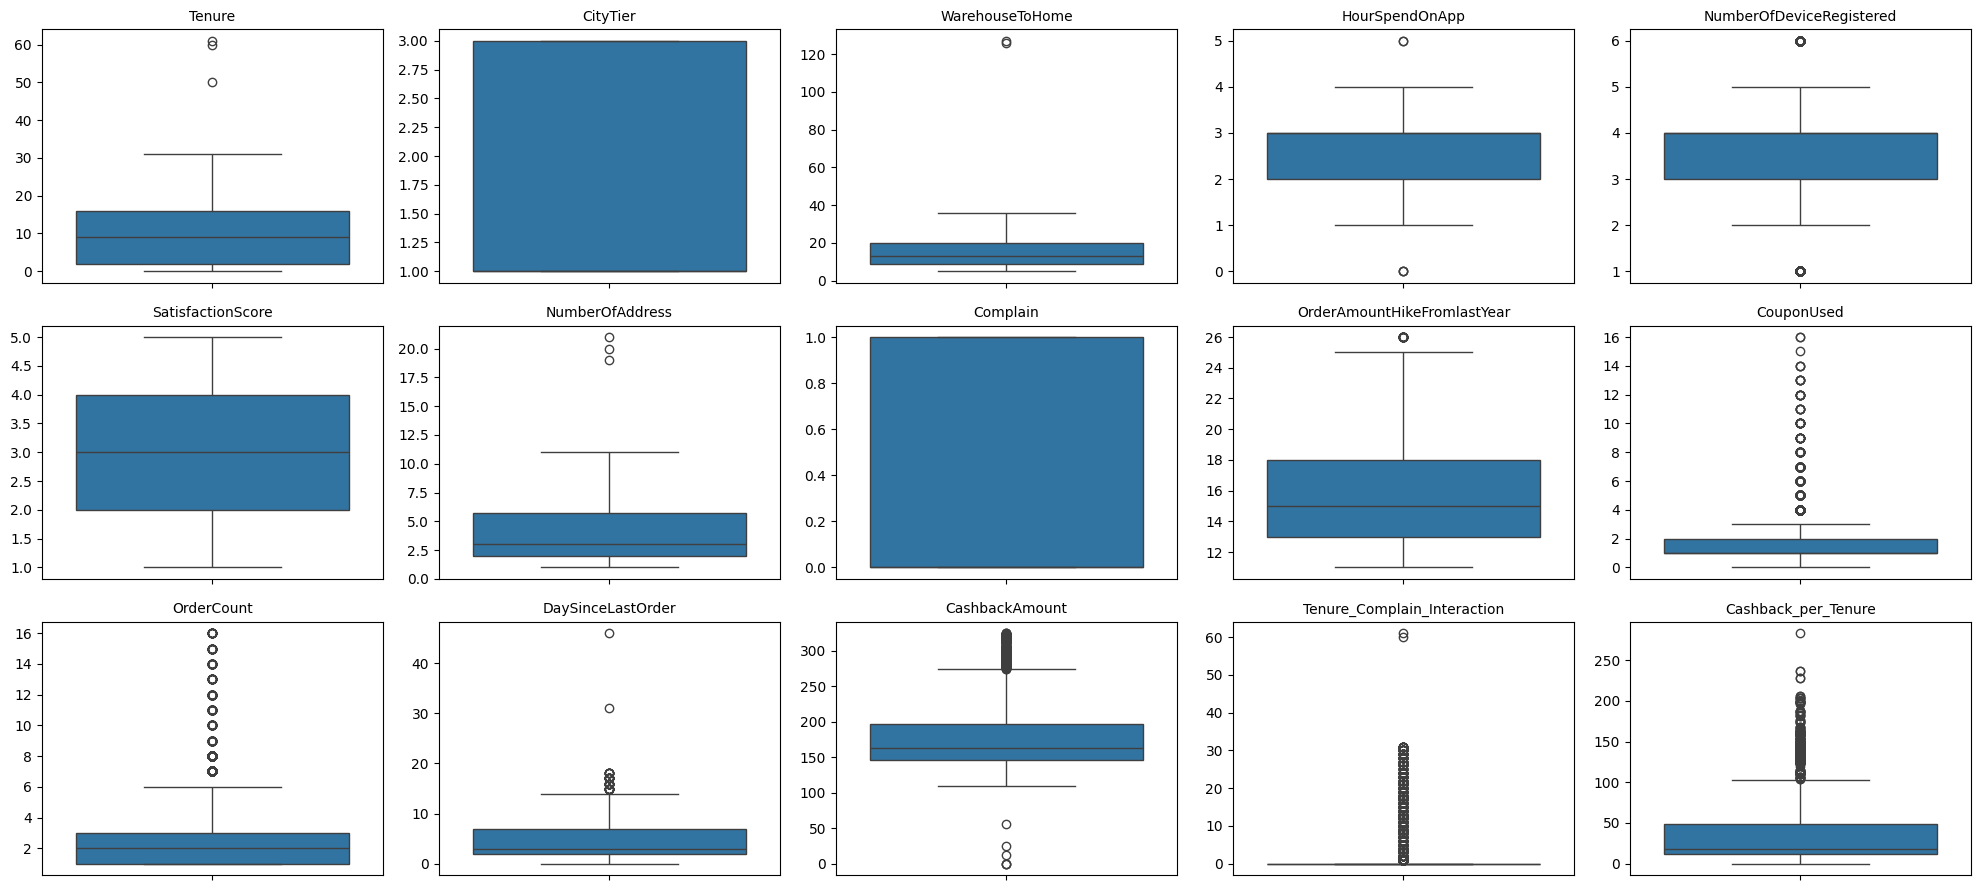

In [53]:
num_eda = [c for c in train_df.select_dtypes(include='number').columns if c != 'Churn']

fig, axes = plt.subplots(3, 5, figsize=(20,9))
for ax, col in zip(axes.ravel(), num_eda):
  sns.boxplot(y=train_df[col], ax=ax)
  ax.set_title(col, fontsize=10)
  ax.set_ylabel('')
for ax in axes.ravel()[len(num_eda):]:
  ax.axis('off')
plt.tight_layout()
plt.show()

###Visualisasi

Text(0, 0.5, '')

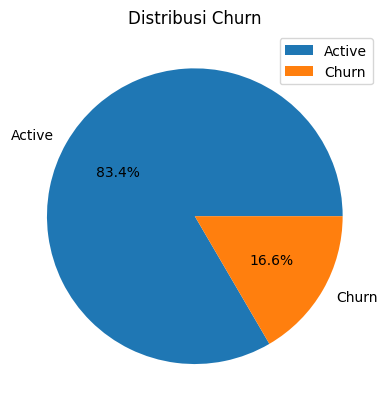

In [54]:
#Churn Overview
train_df['Churn'].value_counts().plot.pie(labels=['Active','Churn'], autopct='%1.1f%%')
plt.title('Distribusi Churn')
plt.legend()
plt.ylabel('')

###Heatmap Spearman Correlation

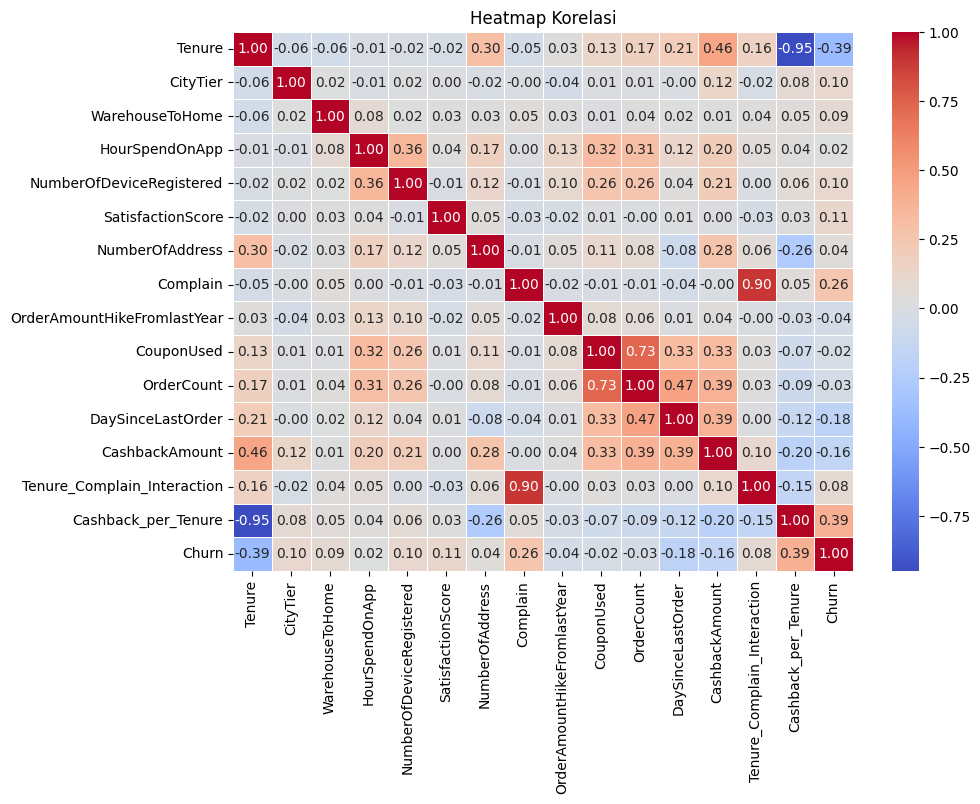

In [55]:
train_df_num = train_df.select_dtypes(include='number')
corr = train_df_num.corr(method='spearman')
plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi')
plt.show()

### Insight dari EDA data train
Heatmap Spearman dipakai karena beberapa fitur memiliki outlier ekstrem (misalnya `WarehouseToHome` maksimal 127); korelasi peringkat lebih tahan terhadap outlier daripada Pearson.

EDA ini bersifat **eksploratif dan deskriptif**. Tidak ada fitur yang dibuang berdasarkan EDA, semua fitur tetap masuk ke model, dan kontribusi akhirnya dinilai dari SHAP. Keputusan ini mencegah *data snooping* berubah menjadi pemilihan fitur yang bias.

---



# **MODELING**



In [56]:
cat_cols = ['MaritalStatus', 'PreferredLoginDevice', 'Gender', 'PreferredPaymentMode', 'PreferedOrderCat']
num_cols = [c for c in feature.columns if c not in cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('target encoder', TargetEncoder(smooth='auto', random_state=20), cat_cols),
        ('scaler',RobustScaler(), num_cols)
    ],
    remainder='passthrough'
)

### Preprocessing: kenapa TargetEncoder + RobustScaler
**Kenapa `TargetEncoder`, bukan `OneHotEncoder`?**
- Dataset hanya punya 5 kolom kategorik dengan kardinalitas rendah (2–6 kategori).
- `TargetEncoder` mengganti tiap kategori dengan rata-rata target yang sudah di *smoothing*, sehingga menghasilkan satu kolom numerik per fitur dan tidak menambah dimensi.


**Kenapa `RobustScaler`?**
Beberapa fitur numerik punya outlier (`WarehouseToHome` sampai 127, `NumberOfAddress` sampai 21). `RobustScaler` memakai median dan IQR, sehingga tidak terpengaruh nilai ekstrem.

**Kenapa semua di dalam `ColumnTransformer`?**
Karena transformer akan di fit ulang pada setiap fold CV. Ini prinsip utama yang membuat seluruh alur bebas leakage.

Kolom kategorik ditentukan secara dinamis dengan `select_dtypes(exclude='number')`, sehingga fitur turunan numerik otomatis masuk ke `num_cols`.

---



In [57]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=20)
scoring = ['accuracy','precision', 'recall', 'f1']

### Kenapa StratifiedKFold 5-fold

`StratifiedKFold(n_splits=5, shuffle=True, random_state=20)` dipakai di seluruh proses: base model, tuning, threshold, dan learning curve.

- **Stratified** → rasio churn 16,8% dijaga di setiap fold, sehingga skor tiap fold bisa dibandingkan.
- **5 fold** → kompromi antara stabilitas estimasi dan biaya komputasi (80% latih, 20% validasi per fold).
- **shuffle + random_state** → pengacakan terkontrol agar hasil reproducible.

Menggunakan CV yang sama di semua tahap membuat perbandingan antar model adil.

---



#Base Model

###KNN

In [58]:
#Base Model
pipeline_base_knn = Pipeline([
    ('preprocessor', preprocessor),
    ('imputer', KNNImputer()),
    ('model', KNeighborsClassifier())
])

knn_base = cross_validate(pipeline_base_knn, X_train, y_train, cv=cv, scoring=scoring)
knn_base_folds = {'Folds': range(1,6)}

for metric in scoring:
  col_knn_base = f"KNN Base {metric.capitalize()}"
  knn_base_folds[col_knn_base] = knn_base[f'test_{metric}']

result_knn_base = pd.DataFrame(knn_base_folds)
display(result_knn_base.round(4))
display(result_knn_base.mean().round(2))

,Folds,KNN Base Accuracy,KNN Base Precision,KNN Base Recall,KNN Base F1
0,1,0.8658,0.6204,0.4963,0.5514
1,2,0.8867,0.7312,0.5037,0.5965
2,3,0.8892,0.7368,0.5185,0.6087
3,4,0.8927,0.7831,0.4851,0.5991
4,5,0.8878,0.7172,0.5299,0.6094


,0
Folds,3.00
KNN Base Accuracy,0.88
KNN Base Precision,0.72
KNN Base Recall,0.51
KNN Base F1,0.59


###Support Vector Machine (SVM)

In [59]:
#Base Model
pipeline_base_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('imputer', KNNImputer()),
    ('model', SVC(probability=True,random_state=20))
])

svm_base = cross_validate(pipeline_base_svm, X_train, y_train, cv=cv, scoring=scoring)
svm_base_folds = {'Folds': range(1,6)}
for metric in scoring:
  col_svm_base = f"SVM Base {metric.capitalize()}"
  svm_base_folds[col_svm_base] = svm_base[f'test_{metric}']
result_svm_base = pd.DataFrame(svm_base_folds)
display(result_svm_base.round(4))
display(result_svm_base.mean().round(2))

,Folds,SVM Base Accuracy,SVM Base Precision,SVM Base Recall,SVM Base F1
0,1,0.8732,0.6569,0.4963,0.5654
1,2,0.8966,0.8228,0.4815,0.6075
2,3,0.8830,0.7703,0.4222,0.5455
3,4,0.9038,0.8415,0.5149,0.6389
4,5,0.8829,0.7407,0.4478,0.5581


,0
Folds,3.00
SVM Base Accuracy,0.89
SVM Base Precision,0.77
SVM Base Recall,0.47
SVM Base F1,0.58


###Logistic Regression


In [60]:
#Base Model
pipeline_base_logres = Pipeline([
    ('preprocessor', preprocessor),
    ('imputer', KNNImputer()),
    ('model', LogisticRegression(random_state=20))
])

logres_base = cross_validate(pipeline_base_logres, X_train, y_train, cv=cv, scoring=scoring)
logres_base_folds = {'Folds': range(1,6)}
for metric in scoring:
  col_logres_base = f"Logres Base {metric.capitalize()}"
  logres_base_folds[col_logres_base] = logres_base[f'test_{metric}']

result_logres_base = pd.DataFrame(logres_base_folds)
display(result_logres_base.round(4))
display(result_logres_base.mean().round(2))

,Folds,Logres Base Accuracy,Logres Base Precision,Logres Base Recall,Logres Base F1
0,1,0.8732,0.6481,0.5185,0.5761
1,2,0.9089,0.8427,0.5556,0.6696
2,3,0.8842,0.7470,0.4593,0.5688
3,4,0.9075,0.8242,0.5597,0.6667
4,5,0.8829,0.7053,0.5000,0.5852


,0
Folds,3.00
Logres Base Accuracy,0.89
Logres Base Precision,0.75
Logres Base Recall,0.52
Logres Base F1,0.61


###Random Forest


In [61]:
#Base Model
pipeline_base_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('imputer', KNNImputer()),
    ('model', RandomForestClassifier(random_state=20))
])

rf_base = cross_validate(pipeline_base_rf, X_train, y_train, cv=cv, scoring=scoring)

rf_base_folds = {'Folds': range(1,6)}
for metric in scoring:
  col_rf_base = f"RF Base {metric.capitalize()}"
  rf_base_folds[col_rf_base] = rf_base[f'test_{metric}']

result_rf_base = pd.DataFrame(rf_base_folds)
display(result_rf_base.round(4))
display(result_rf_base.mean().round(2))

,Folds,RF Base Accuracy,RF Base Precision,RF Base Recall,RF Base F1
0,1,0.9286,0.8667,0.6741,0.7583
1,2,0.9421,0.8929,0.7407,0.8097
2,3,0.9433,0.9588,0.6889,0.8017
3,4,0.9334,0.8774,0.6940,0.7750
4,5,0.9285,0.8725,0.6642,0.7542


,0
Folds,3.00
RF Base Accuracy,0.94
RF Base Precision,0.89
RF Base Recall,0.69
RF Base F1,0.78


###XGBoost

In [62]:
#Base Model XGB
pipeline_base_xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('imputer', KNNImputer()),
    ('model', XGBClassifier(scale_pos_weight=5,random_state=20))
])

xgb_base = cross_validate(pipeline_base_xgb, X_train, y_train, cv=cv, scoring=scoring)

xgb_base_folds = {'Folds': range(1,6)}
for metric in scoring:
  col_xgb_base = f"XGB Base {metric.capitalize()}"
  xgb_base_folds[col_xgb_base] = xgb_base[f'test_{metric}']

result_xgb_base = pd.DataFrame(xgb_base_folds)
display(result_xgb_base.round(4))
display(result_xgb_base.mean().round(2))

,Folds,XGB Base Accuracy,XGB Base Precision,XGB Base Recall,XGB Base F1
0,1,0.9520,0.8582,0.8519,0.8550
1,2,0.9557,0.8722,0.8593,0.8657
2,3,0.9532,0.8702,0.8444,0.8571
3,4,0.9482,0.8538,0.8284,0.8409
4,5,0.9544,0.8760,0.8433,0.8593


,0
Folds,3.00
XGB Base Accuracy,0.95
XGB Base Precision,0.87
XGB Base Recall,0.85
XGB Base F1,0.86


###Comparing Base Model

In [63]:
base_folds = {
    'KNN': result_knn_base['KNN Base Recall'],
    'SVM': result_svm_base['SVM Base Recall'],
    'Logistic Regression': result_logres_base['Logres Base Recall'],
    'Random Forest': result_rf_base['RF Base Recall'],
    'XGBoost': result_xgb_base['XGB Base Recall']
}

# Membuat DataFrame perbandingan dan mengganti indeks secara aman
fold_df = pd.DataFrame(base_folds)
fold_df.index = [f'Fold {i}' for i in range(1, 6)]
fold_df = fold_df.T

# Menghitung rata-rata performa fold
fold_df['Mean'] = fold_df.mean(axis=1)

print("=== Perbandingan Recall Base Model per Fold ===")
display(fold_df.round(4).sort_values('Mean', ascending=False))

=== Perbandingan Recall Base Model per Fold ===


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean
XGBoost,0.8519,0.8593,0.8444,0.8284,0.8433,0.8454
Random Forest,0.6741,0.7407,0.6889,0.6940,0.6642,0.6924
Logistic Regression,0.5185,0.5556,0.4593,0.5597,0.5000,0.5186
KNN,0.4963,0.5037,0.5185,0.4851,0.5299,0.5067
SVM,0.4963,0.4815,0.4222,0.5149,0.4478,0.4725


### Kenapa XGBoost dipilih, dan kenapa pakai `scale_pos_weight`

Lima base model diuji dengan pipeline yang identik.
XGBoost unggul karena kemampuannya menangkap **interaksi non-linear** antarfitur (misalnya komplain × tenure) secara otomatis, tanpa perlu spesifikasi manual.

**Kenapa `scale_pos_weight=5` dan bukan SMOTE?**
Rasio kelas setelah deduplikasi adalah 0,834 / 0,166 ≈ **5**. Memberi bobot 5× pada kelas churn di fungsi loss sudah cukup membuat model sensitif terhadap minoritas. SMOTE tidak dipakai karena:
- Data sintetis dapat mengaburkan batas keputusan pada dataset kecil (~4 ribu baris latih).
- `scale_pos_weight` lebih sederhana, terpasang langsung di model, dan tidak mengubah jumlah baris saat CV.

Karena biaya FN hampir 5× biaya FP, **recall lebih diutamakan**, sehingga XGBoost menjadi kandidat final.Metode yang sama dipakai di model base maupun model tuned, sehingga perbandingan keduanya adil.

---



#Final Model (Hyperparameter Tuning)


###XGBoost Tuning

In [64]:
xgb_params = {
    'model__n_estimators':      [200, 300, 400],
    'model__learning_rate':     [0.03, 0.05],
    'model__max_depth':         [3, 4],
    'model__min_child_weight':  [5, 10],
    'model__subsample':         [0.8, 0.9],
    'model__colsample_bytree':  [0.8, 0.9],
    'model__reg_lambda':        [5, 10],
    'model__scale_pos_weight':  [5],
}

random_search_xgb = RandomizedSearchCV(
    estimator=pipeline_base_xgb,
    param_distributions=xgb_params,
    scoring='recall',
    n_iter=50,
    cv=cv,
    verbose=1,
    random_state=20,
    n_jobs=-1
)

random_search_xgb.fit(X_fit, y_fit)
xgb_val = random_search_xgb.best_estimator_
print(f"\nParameter Terbaik (XGBoost dengan scale_pos_weight): {random_search_xgb.best_params_}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits

Parameter Terbaik (XGBoost dengan scale_pos_weight): {'model__subsample': 0.9, 'model__scale_pos_weight': 5, 'model__reg_lambda': 5, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}


### Hyperparameter tuning: kenapa RandomizedSearchCV

**Kenapa Randomized, bukan Grid?**
Grid berisi 3 × 2 × 2 × 2 × 2 × 2 × 2 × 1 = **96 kombinasi**. Dengan 5-fold CV itu berarti 480 fit. `RandomizedSearchCV` mengambil 50 kombinasi acak, cukup untuk mencari ruang parameter dengan biaya hampir setengahnya.

**Kenapa `scoring='recall'`?**
Selaras dengan cost matrix: FN jauh lebih mahal daripada FP. Metrik lain seperti accuracy akan mendorong model menjadi konservatif.

**Kenapa fit hanya di `X_fit`?**
Supaya `X_val` tetap bersih untuk memilih threshold, dan `X_test` tetap tersegel untuk evaluasi akhir.

**Arti parameter yang di-tuning:**

| Parameter | Fungsi | Nilai terbaik |
|---|---|---|
| `n_estimators` | Jumlah tree; terlalu banyak → hafalan | 300 |
| `learning_rate` | Besar kontribusi tiap tree | 0,05 |
| `max_depth` | Kedalaman tree; dalam → kompleks | 4 |
| `min_child_weight` | Minimum bobot daun; cegah daun dari sedikit sampel | 5 |
| `subsample` | Persentase baris per tree | 0,9 |
| `colsample_bytree` | Persentase fitur per tree | 0,8 |
| `reg_lambda` | Penalti L2 pada bobot | 5 |
| `scale_pos_weight` | Bobot kelas churn | 5 |




In [65]:
cv_base = cross_validate(pipeline_base_xgb, X_fit, y_fit,
                         cv=cv, scoring='recall', n_jobs=-1)
cv_tune = cross_validate(xgb_val, X_fit, y_fit,
                         cv=cv, scoring='recall', n_jobs=-1)
print(f'Base Recall = {cv_base['test_score'].mean():.4f}')
print(f"Tuned Recall = {cv_tune['test_score'].mean():.4f}")

Base Recall = 0.7918
Tuned Recall = 0.8346


##Threshold

###XGB Threshold

In [66]:
proba_val = xgb_val.predict_proba(X_val)[:,1]

results = []
for t in np.arange(0.05, 0.96, 0.01):
  pred = (proba_val >= t).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
  loss = fn * 67_680 + fp * 14_700
  results.append((round(t, 2), loss))
best_threshold, best_loss = min(results, key=lambda x: x[1])

print('==== Best XGBoost Threshold ====')
print(f'Threshold terbaik: {best_threshold}')
print(f'Kerugian minimum: Rp{best_loss:,.0f}')

==== Best XGBoost Threshold ====
Threshold terbaik: 0.5
Kerugian minimum: Rp2,447,520


### Threshold cost-sensitive: kenapa 0,50

Model menghasilkan **probabilitas**, bukan label. Threshold menentukan di mana probabilitas diubah menjadi keputusan "churn".

Threshold dicari di `X_val` (bukan test) dengan grid 0,05–0,95 langkah 0,01 dan fungsi biaya:

```python
loss = fn * 67_680 + fp * 14_700
```

**Hasil: threshold optimal = 0,50**, dengan kerugian validation **Rp 2.447.520**.

Ini kabar baik: titik optimal menurut fungsi biaya **berimpitan dengan default**. Artinya model tidak memerlukan ambang khusus yang sulit dijelaskan, dan narasi bisnis menjadi sederhana:

> Jika probabilitas churn ≥ 0,50 → masukkan pelanggan ke daftar kampanye retensi.

Jika threshold optimal jauh dari 0,50, kita harus menyesuaikan pipeline deployment. Karena tidak demikian, model final memakai keputusan default tanpa komplikasi tambahan.

Grid diperlebar sampai 0,05–0,95 (langkah 0,01) supaya tidak ada optimum yang terlewat akibat grid terlalu jarang.

---



In [67]:
#Model final tuned + threshold
xgb_final = clone(random_search_xgb.best_estimator_).fit(X_train, y_train)

In [68]:
y_proba_test_xgb = xgb_final.predict_proba(X_test)[:,1]
y_pred_thres_xgb = (y_proba_test_xgb >= best_threshold).astype(int)

print("===== SETELAH TUNING & THRESHOLD =====")
print(confusion_matrix(y_test, y_pred_thres_xgb))
print(classification_report(y_test, y_pred_thres_xgb))
print(f'ROC AUC: {roc_auc_score(y_test, y_proba_test_xgb):.4f}')

===== SETELAH TUNING & THRESHOLD =====
[[787  60]
 [ 20 148]]
              precision    recall  f1-score   support

           0       0.98      0.93      0.95       847
           1       0.71      0.88      0.79       168

    accuracy                           0.92      1015
   macro avg       0.84      0.91      0.87      1015
weighted avg       0.93      0.92      0.92      1015

ROC AUC: 0.9604


### Evaluasi akhir di data test

Data test (**1.015 baris**) baru dipakai di sini untuk pertama kalinya setelah semua keputusan dikunci.

```
[[787  60]
 [ 20 148]]
```

| Metrik | Nilai | Arti |
|---|---|---|
| Precision | 0,71 | Dari 208 pelanggan yang diprediksi churn, 148 benar churn |
| Recall | 0,88 | Dari 168 pelanggan churn, 148 berhasil ditangkap |
| F1 | 0,79 | Rata-rata harmonis precision–recall |
| Accuracy | 0,92 | 935 dari 1.015 prediksi benar |
| ROC AUC | 0,960 | Model sangat baik memeringkat probabilitas churn |

**Dampak finansial:**

```
FN = 20 → 20 × Rp 67.680 = Rp 1.353.600
FP = 60 → 60 × Rp 14.700 =    Rp 882.000
Total                    = Rp 2.235.600
```

---



#Confusion Matrix Final Model (XGBoost)

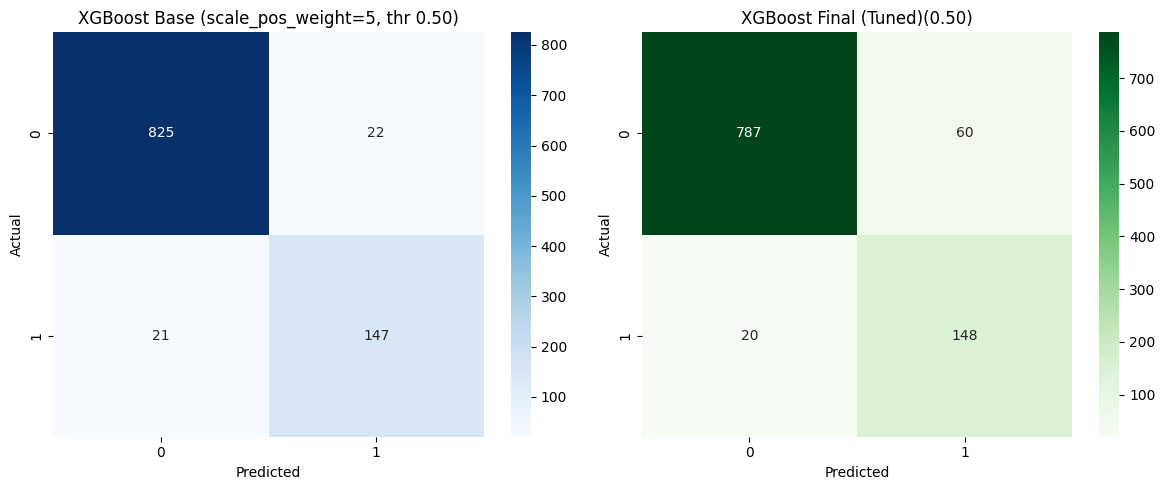

In [69]:
y_pred_base = (pipeline_base_xgb.fit(X_train, y_train)
              .predict_proba(X_test)[:,1] >= 0.5).astype(int)
cm_before = confusion_matrix(y_test, y_pred_base)
cm_after = confusion_matrix(y_test, y_pred_thres_xgb)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm_before, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('XGBoost Base (scale_pos_weight=5, thr 0.50)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_after, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'XGBoost Final (Tuned)({best_threshold:.2f})')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### Membaca confusion matrix secara bisnis

| Kuadran | Jumlah | Makna operasional |
|---|---|---|
| **TN** = 787 | 787 | Pelanggan sehat dikenali dengan benar → tidak ada biaya |
| **FP** = 60 | 60 | Kampanye retensi diberikan sia-sia → biaya Rp 882.000 |
| **FN** = 20 | 20 | Pelanggan churn terlewat → biaya Rp 1.353.600 |
| **TP** = 148 | 148 | Churn terdeteksi → potensi penyelamatan pelanggan |

Panel kiri adalah model base, panel kanan model final. Keduanya memakai `scale_pos_weight=5`; perbedaannya ada pada hyperparameter hasil tuning.

---



#ROC Curve (XGBoost)

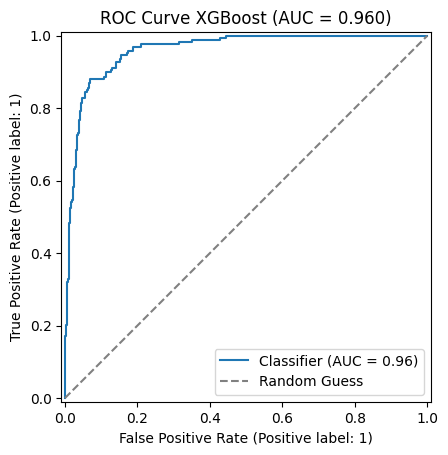

In [70]:
y_test_proba_xgb = xgb_final.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, y_test_proba_xgb)

RocCurveDisplay.from_predictions(y_test, y_test_proba_xgb)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.title(f"ROC Curve XGBoost (AUC = {auc_score:.3f})")
plt.legend()
plt.show()

### ROC Curve

Kurva ROC menjawab satu pertanyaan: **seberapa baik model memisahkan pelanggan churn dari pelanggan active, terlepas dari threshold yang dipakai?**

**Cara membaca sumbunya:**

| Sumbu | Nama | Arti |
|---|---|---|
| X | False Positive Rate (FPR) | Dari semua pelanggan yang sebenarnya **active**, berapa persen yang salah diprediksi sebagai churn |
| Y | True Positive Rate (TPR) / recall | Dari semua pelanggan yang benar-benar **churn**, berapa persen yang berhasil ditemukan model |

Setiap titik di kurva adalah pasangan (FPR, TPR) untuk **satu nilai threshold**. Menurunkan threshold menaikkan TPR sekaligus menaikkan FPR — itulah trade-off yang terlihat sebagai bentuk kurva.

Garis putus-putus abu adalah **tebakan acak** (AUC = 0,5): model tidak punya kemampuan membedakan dua kelas. Semakin jauh kurva ke arah kiri-atas, semakin baik model.

**Arti AUC = 0,960:**
Jika kita mengambil secara acak satu pelanggan yang benar-benar churn dan satu pelanggan yang benar-benar active, model akan memberi **probabilitas churn yang lebih tinggi kepada pelanggan churn dalam sekitar 96 dari 100 percobaan**.

**Kenapa AUC dipasang di sini dan bukan menggantikan recall?**
AUC **tidak berubah saat threshold diubah** — threshold hanya memindahkan posisi titik di sepanjang kurva, bukan mengubah bentuk kurvanya. Karena itu:

- **AUC** → menilai kualitas model secara keseluruhan (ranking probabilitas).
- **Recall / precision di threshold 0,50** → menilai keputusan operasional yang benar-benar dipakai.

Keduanya menjawab pertanyaan yang berbeda, jadi keduanya perlu ditampilkan.

**Implikasi bisnis:**
Karena urutan probabilitasnya baik, daftar pelanggan bisa diurutkan dari yang paling berisiko ke yang paling aman. Jika budget kampanye retensi terbatas, tim bisa memprioritaskan pelanggan dengan probabilitas tertinggi terlebih dahulu,bukan sekadar memberi perlakuan yang sama kepada semua pelanggan yang berstatus "churn".

---

### Learning Curve


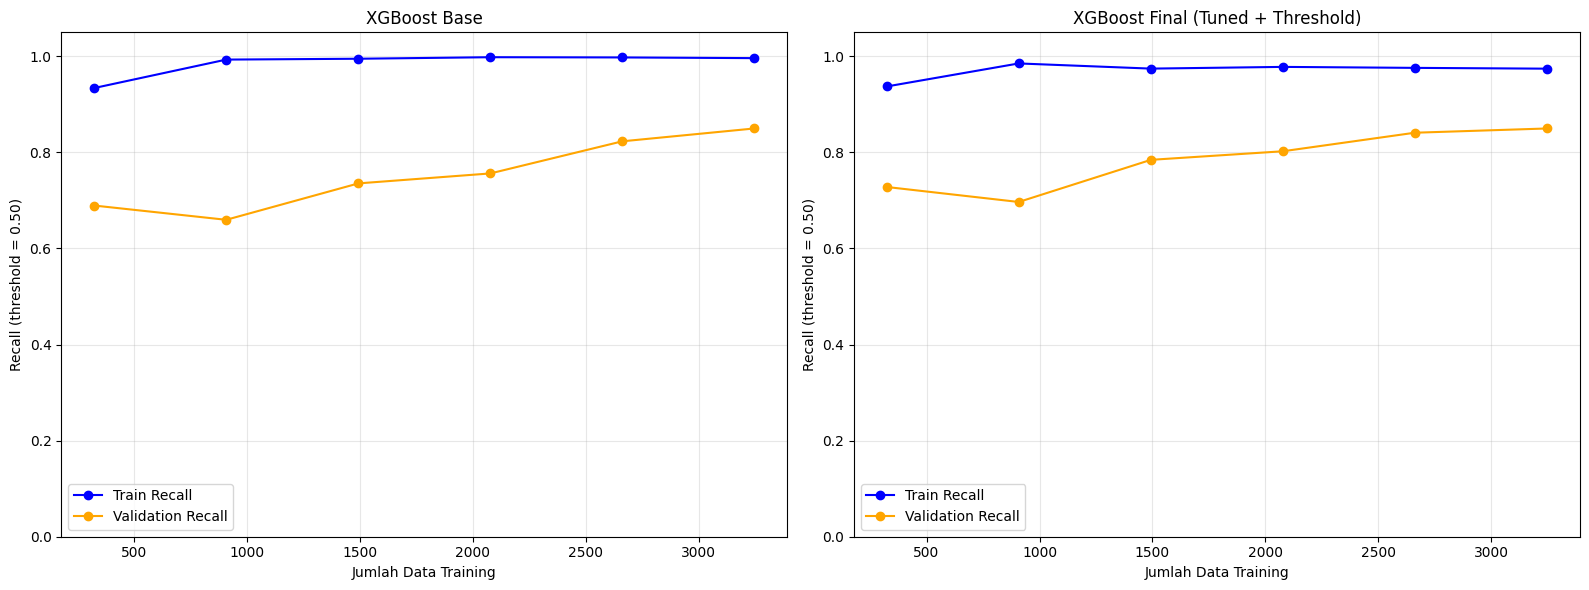

,Model,Train Recall (OOF),Test Recall,Gap
0,XGBoost Final,0.8544,0.881,-0.0266


In [71]:
scorer = make_scorer(
    lambda y_true, p: recall_score(y_true, (p >= best_threshold).astype(int)),
    response_method='predict_proba'
)

sizes_b, train_b, val_b = learning_curve(
    clone(pipeline_base_xgb), X_train, y_train,
    cv=cv, scoring=scorer, train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1
)

sizes_f, train_f, val_f = learning_curve(
    clone(xgb_final), X_train, y_train,
    cv=cv, scoring=scorer, train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

panels = [
    (axes[0], sizes_b, train_b, val_b, 'XGBoost Base'),
    (axes[1], sizes_f, train_f, val_f, 'XGBoost Final (Tuned + Threshold)')
]

for ax, sizes, train_s, val_s, title in panels:
    ax.plot(sizes, train_s.mean(axis=1), 'o-', color='blue',  label='Train Recall')
    ax.plot(sizes, val_s.mean(axis=1),   'o-', color='orange', label='Validation Recall')
    ax.set_xlabel('Jumlah Data Training')
    ax.set_ylabel(f'Recall (threshold = {best_threshold:.2f})')
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

oof = cross_val_predict(clone(xgb_final), X_train, y_train,
                        cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

gap_df = pd.DataFrame({
    'Model': ['XGBoost Final'],
    'Train Recall (OOF)': [recall_score(y_train, (oof >= best_threshold).astype(int))],
    'Test Recall': [recall_score(y_test,
                     (xgb_final.predict_proba(X_test)[:, 1] >= best_threshold).astype(int))]
})

gap_df['Gap'] = gap_df['Train Recall (OOF)'] - gap_df['Test Recall']
display(gap_df.round(4))

### Diagnosa overfitting: kenapa memakai OOF

#### 1. Kenapa `predict(X_train)` menyesatkan

Setelah model di-fit pada `X_train`, memanggil `predict(X_train)` berarti **menanyai model tentang data yang baru saja ia hafal**. Skor yang keluar bukan ukuran kemampuan mengenali pola baru, melainkan ukuran kemampuan mengulang jawaban yang sudah dilihat.

Untuk XGBoost yang fleksibel, train recall hampir selalu mendekati 1,0 secara konstruksi. Jika angka in-sample itu dibandingkan dengan recall data test, gap-nya akan besar, tetapi gap tersebut **bukan bukti overfitting**, melainkan akibat cara mengukur yang keliru.

#### 2. Apa itu OOF (Out-of-Fold)?

OOF adalah prediksi yang dibuat oleh model yang **tidak pernah melihat baris itu saat dilatih**. Caranya memakai 5-fold cross-validation:

```text
Data latih dibagi 5 bagian: F1 F2 F3 F4 F5

Putaran 1 : latih [F2 F3 F4 F5] → prediksi F1
Putaran 2 : latih [F1 F3 F4 F5] → prediksi F2
Putaran 3 : latih [F1 F2 F4 F5] → prediksi F3
Putaran 4 : latih [F1 F2 F3 F5] → prediksi F4
Putaran 5 : latih [F1 F2 F3 F4] → prediksi F5
```

Setiap baris tepat **satu kali** berperan sebagai data validation. Kelima hasil prediksi digabung menjadi satu vektor OOF sepanjang data latih. Di notebook ini, fungsi yang melakukan hal itu adalah:

```python
cross_val_predict(clone(xgb_final), X_train, y_train,
                  cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
```

ARGUMEN PENTING:
- `clone(xgb_final)` → menyalin arsitektur + hyperparameter tanpa bobot hasil fit, supaya tiap fold benar-benar dilatih ulang.
- `method='predict_proba'` → menghasilkan probabilitas, sehingga bisa diterapkan `best_threshold`.
- `cv=cv` → memakai `StratifiedKFold` yang sama dengan tahap lainnya.

#### 3. Kenapa OOF lebih jujur?

Karena **tidak ada baris yang diprediksi oleh model yang menghafalnya**. OOF mensimulasikan kondisi "data baru" hanya dengan memakai data latih yang sudah ada.

Perbandingan yang benar:

```
Train Recall (OOF) = 0,8544   ← tiap baris diprediksi model yang tidak melihatnya
Test Recall        = 0,8810   ← data yang benar-benar tidak pernah dipakai
Gap                = -0,0266
```

Gap kecil dan **negatif** artinya performa di test tidak lebih rendah dari rata-rata OOF. Tidak ada indikasi overfitting. Selisih negatif kecil masih masuk dalam rentang wajar akibat perbedaan sampel.

#### 4. Apakah ini underfitting?

Bukan.garis validation masih naik sedikit di ujung. Artinya **data tambahan masih bisa menaikkan performa**, bukan bahwa model terlalu sederhana.

#### 5. Kenapa scorer learning curve memakai `best_threshold`?

Supaya kurva model base dan model final diukur dengan **aturan keputusan yang sama**. Jika satu memakai 0,50 dan yang lain 0,32, perbandingan kedua kurva menjadi tidak sejajar, selisihnya bisa berasal dari threshold, bukan dari kualitas model.

---

#Feature Importance & SHAP


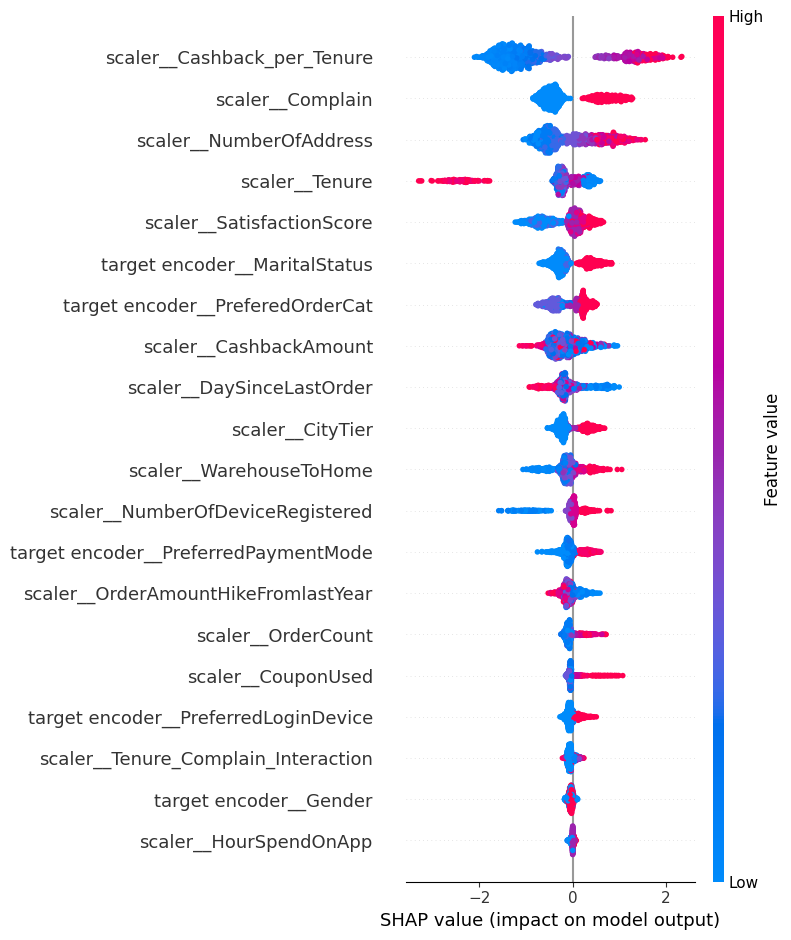

In [72]:
feature_names = xgb_final.named_steps['preprocessor'].get_feature_names_out()
importances = xgb_final.named_steps['model'].feature_importances_
feat_imp_df = (pd.DataFrame({'Feature': feature_names, 'Importance': importances})
              .sort_values('Importance', ascending=False).reset_index(drop=True))
X_test_tf = xgb_final.named_steps['imputer'].transform(
    xgb_final.named_steps['preprocessor'].transform(X_test)
)

X_test_tf_df = pd.DataFrame(X_test_tf, columns=feature_names)

explainer = shap.TreeExplainer(xgb_final.named_steps['model'])
sv = explainer(X_test_tf)
sv_plot = sv[:, :, 1] if sv.values.ndim == 3 else sv

shap.summary_plot(sv_plot, X_test_tf_df, show=False)
plt.tight_layout()
plt.show()

### SHAP: kenapa dipakai dan apa yang ditemukan

`feature_importances_` dari XGBoost hanya menunjukkan **seberapa sering** fitur dipakai untuk split, tidak menunjukkan arah pengaruhnya. **SHAP (SHapley Additive exPlanations)** menghitung kontribusi tiap fitur ke **prediksi individual**, lengkap dengan arah:

- SHAP value **positif** (kanan) → mendorong prediksi ke arah **churn**.
- SHAP value **negatif** (kiri) → mendorong prediksi ke arah **active**.
- Warna merah = nilai fitur tinggi, biru = nilai fitur rendah.

#### Insight utama dari summary plot

| Peringkat | Fitur | Arah & interpretasi |
|---|---|---|
| **1** | `Cashback_per_Tenure` | Paling dominan. Nilai **tinggi** (merah) mendorong ke churn, nilai rendah (biru) ke active. Fitur buatan ini ternyata paling informatif — pelanggan dengan cashback besar relatif terhadap tenure-nya berisiko tinggi. |
| **2** | `Complain` | Sangat jelas: `Complain = 1` (merah) → churn, `0` (biru) → active. |
| **3** | `NumberOfAddress` | Jumlah alamat tinggi (merah) cenderung mendorong churn, mengindikasikan profil pelanggan yang lebih kompleks atau sering berpindah. |
| **4** | `Tenure` | Nilai **tinggi** (merah) berada di sisi negatif → pelanggan lama cenderung **active**. Ini kebalikan dari fitur pertama dan masuk akal secara domain. |
| **5** | `SatisfactionScore` | Muncul di peringkat atas, namun arahnya perlu dibaca bersama fitur lain karena korelasi dengan `Complain` dan `Cashback_per_Tenure`. |

Fitur dengan kontribusi kecil (hampir di nol): `Tenure_Complain_Interaction`, `Gender`, `HourSpendOnApp`, `PreferredLoginDevice`. Artinya:

- Dari dua fitur buatan, **hanya `Cashback_per_Tenure` yang sangat penting**; `Tenure_Complain_Interaction` memberi kontribusi marginal. Ini temuan jujur yang bisa dipakai untuk penyederhanaan model di masa depan.
- `Gender` dan `HourSpendOnApp` hampir tidak membedakan churn.

#### Kenapa SHAP lebih dipercaya daripada feature importance

Dua pelanggan dengan nilai fitur sama bisa mendapat prediksi berbeda karena interaksi. SHAP menjelaskan **setiap prediksi secara individual**, sehingga bisa menjawab: *"kenapa pelanggan ini diberi probabilitas churn 0,8?"* — sesuatu yang tidak bisa dijawab oleh feature importance global.

---



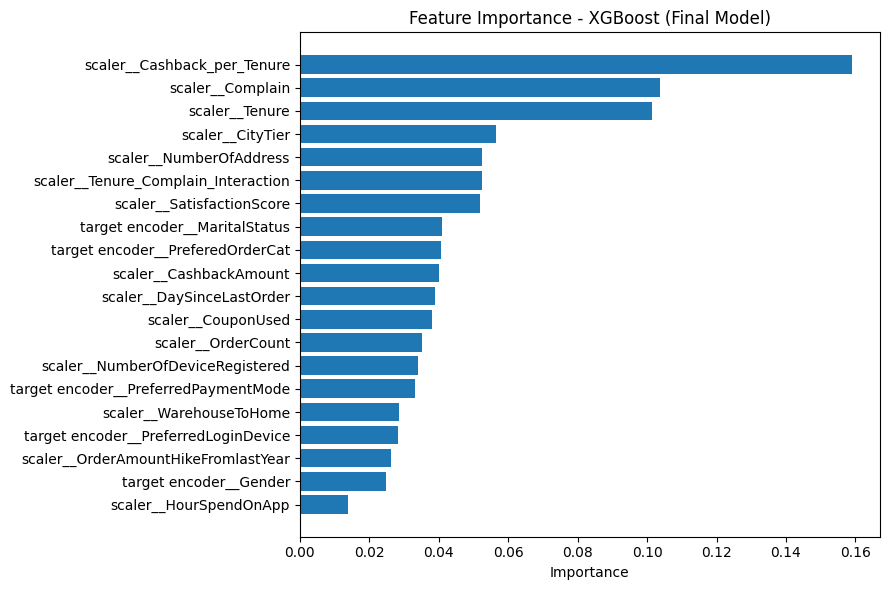

In [73]:
plt.figure(figsize=(9, 6))
plt.barh(feat_imp_df['Feature'][::-1], feat_imp_df['Importance'][::-1])
plt.xlabel('Importance')
plt.title('Feature Importance - XGBoost (Final Model)')
plt.tight_layout()
plt.show()

### Feature importance vs SHAP — ringkasan perbandingan

Feature importance XGBoost menempatkan Cashback_per_Tenure (~0,16) di puncak, diikuti Complain (~0,105), Tenure (~0,10), CityTier (~0,057), `NumberOfAddress` dan `Tenure_Complain_Interaction` (~0,055).

Urutan ini **sebagian besar konsisten** dengan SHAP, tetapi ada perbedaan kecil — misalnya `NumberOfAddress` lebih menonjol di SHAP. Ini wajar: feature importance berbasis *gain/split*, SHAP berbasis kontribusi aktual terhadap output. Keduanya saling melengkapi:

- **Feature importance** → ringkasan global, cepat dibaca.
- **SHAP** → arah pengaruh + penjelasan per prediksi.

Kesimpulan interpretasi: **lama berlangganan, komplain, dan rasio cashback terhadap tenure** adalah tiga pilar yang menjelaskan churn di dataset ini.

---





#Saving XGBoost Final Model

In [74]:
joblib.dump({
    'pipeline': xgb_final,
    'threshold': best_threshold,
    'feature_order': list(X_train.columns)},
    'churn_xgb_pipeline.pkl'
)

bundle = joblib.load('churn_xgb_pipeline.pkl')
model, thr = bundle['pipeline'], bundle['threshold']

## Kesimpulan

Berikut ringkasan seluruh project dengan kerangka **STAR (Situation – Task – Action – Result)**, yang menyusun narasi dari konteks masalah, tantangan, langkah yang diambil, hingga dampak yang terukur.

---

### S — Situation (Situasi Awal)

- Platform e-commerce menghadapi **churn sebesar 16,8%** (948 dari 5.630 pelanggan). Jika dibiarkan, pendapatan masa depan hilang.
- Biaya kesalahan tidak simetris: **FN = Rp 67.680** (kehilangan pelanggan) vs **FP = Rp 14.700** (kampanye retensi sia-sia), rasio ≈ **4,6 : 1**.
- Data awal bermasalah: **557 baris duplikat** yang menyebabkan sekitar 180 baris test merupakan salinan dari train, sehingga performa tampak bagus secara palsu.
- Versi awal pemodelan juga menunjukkan **gap train–test yang besar**, bukan karena model benar-benar overfit, tetapi karena skor train diukur secara *in-sample* dan resep preprocessing antara model base dan model final tidak konsisten.

---

### T — Task (Tugas & Tujuan)

1. Membangun model klasifikasi churn yang **bebas data leakage** dan dapat dipercaya sebagai estimasi performa dunia nyata.
2. Mengoptimalkan **recall** sebagai metrik utama, selaras dengan biaya FN yang dominan.
3. Menghasilkan model yang **dapat diinterpretasi** (SHAP) dan **siap di-deploy** bersama preprocessing-nya.
4. Menjamin semua keputusan pemodelan diambil di data latih/validasi, dengan **data test dipakai sekali** di akhir.

---

### A — Action (Tindakan yang Dilakukan)

| No | Tindakan | Alasan |
|---|---|---|
| 1 | Menyamakan ejaan kategori (`Mobile`, `Phone`) | Mencegah sinyal target terpecah saat encoding |
| 2 | Menghapus 557 duplikat **sebelum** split | Menghilangkan train–test leakage |
| 3 | Membuat 2 fitur turunan (`Tenure_Complain_Interaction`, `Cashback_per_Tenure`) | Menangkap interaksi dan rasio yang tidak terlihat pada fitur mentah |
| 4 | Split tiga arah: fit / validation / test (stratified) | Memisahkan pelatihan, pemilihan threshold, dan evaluasi akhir |
| 5 | `TargetEncoder` (cv internal = 5) + `RobustScaler` + `KNNImputer`, semua **di dalam pipeline** | Transformasi di-fit per fold CV → tanpa leakage; tahan outlier |
| 6 | `scale_pos_weight=5` (bukan SMOTE) | Menangani imbalance ≈ 5:1 tanpa data sintetis |
| 7 | Membandingkan 5 base model dengan CV yang sama | XGBoost terpilih (recall 0,845) |
| 8 | `RandomizedSearchCV` 50 iterasi, `scoring='recall'`, fit hanya di `X_fit` | Tuning sistematis tanpa menyentuh validation/test |
| 9 | Threshold cost-sensitive di `X_val` (grid 0,05–0,95) | Memilih titik operasional berdasarkan rupiah, bukan akurasi |
| 10 | Refit model di seluruh data train setelah threshold dikunci | Memaksimalkan data tanpa mengubah keputusan |
| 11 | Evaluasi dengan **OOF** + learning curve | Mengukur overfitting secara jelas (bukan in-sample) |
| 12 | SHAP + feature importance | Menjelaskan arah dan besaran pengaruh tiap fitur |
| 13 | Menyimpan pipeline lengkap + threshold + urutan kolom | Memastikan inference identik dengan training |

---

### R — Result (Hasil yang Dicapai)

**Kinerja model di data test (1.015 baris, dipakai sekali):**

| Metrik | Nilai |
|---|---|
| Recall | **0,88** |
| Precision | **0,71** |
| F1-Score | **0,79** |
| Accuracy | **0,92** |
| ROC AUC | **0,960** |

**Dampak finansial:**

```
FN = 20  × Rp 67.680 = Rp 1.353.600
FP = 60  × Rp 14.700 =    Rp 882.000
Total kerugian       = Rp 2.235.600
```

**Kepercayaan terhadap model:**

- Train Recall (OOF) = 0,8544 vs Test Recall = 0,8810 → **gap −0,0266** (tidak ada overfitting berarti).
- Threshold optimal = **0,50**, berimpitan dengan default → tidak perlu aturan ambang khusus.
- Tidak ada data leakage: seluruh transformasi berada di dalam pipeline dan di-fit hanya pada fold latih.

**Insight interpretasi (SHAP):**

- **`Cashback_per_Tenure`** — fitur hasil rekayasa — menjadi **paling berpengaruh**; nilai tinggi mendorong prediksi churn.
- **`Complain`** dan **`Tenure`** mengikuti sebagai pilar berikutnya, dengan arah yang sesuai domain (komplain → churn, tenure tinggi → active).
- **`Gender`, `HourSpendOnApp`, dan `Tenure_Complain_Interaction`** memberi kontribusi marginal → kandidat untuk penyederhanaan model berikutnya.

**Kesiapan operasional:**

- Artifact `churn_xgb_pipeline.pkl` berisi pipeline + threshold + urutan kolom, siap dipakai.
- Apabila biaya kampanye berubah, threshold dapat disesuaikan tanpa melatih ulang model.

